In [79]:
# import bibliotek
import pandas as pd
import numpy as np
from pathlib import Path

In [80]:
# Ścieżka do folderu z danymi
data_dir = Path("../data")

In [81]:
# Lista wszystkich plików Excel
files = sorted(data_dir.glob("TTex_*.xlsx"))
print(f"Number of files: {len(files)}")

Number of files: 64


In [82]:
# Nazwy arkuszy
sheets = ["Department", "Positon", "Employee", "Car", "Trip"]

In [83]:
# Słownik przechowujący dane z poszczególnych arkuszy
data = {sheet: [] for sheet in sheets}

In [84]:
# Wczytanie danych
for file in files:
    excel_data = pd.read_excel(file, sheet_name=sheets)

    for sheet in sheets:
        data[sheet].append(excel_data[sheet])

In [85]:
# Połączenie danych
df_department = pd.concat(data["Department"], ignore_index=True)
df_position = pd.concat(data["Positon"], ignore_index=True)
df_employee = pd.concat(data["Employee"], ignore_index=True)
df_car = pd.concat(data["Car"], ignore_index=True)
df_trip = pd.concat(data["Trip"], ignore_index=True)

In [86]:
df_department.head(10)

,id,name,description
0,1,GM,General Management
1,2,FI,Finance
2,3,HR,Human Resource
3,4,TR,Transport
4,5,IT,Information technology
5,1,GM,General Management
6,2,FI,Finance
7,3,HR,Human Resource
8,4,TR,Transport
9,5,IT,Information technology


In [87]:
df_department.shape

(320, 3)

In [88]:
df_department.dtypes

id             int64
name             str
description      str
dtype: object

In [89]:
df_department.isna().sum()

id             0
name           0
description    0
dtype: int64

In [90]:
df_department.nunique()

id             5
name           5
description    5
dtype: int64

In [91]:
df_department.duplicated().sum()

np.int64(315)

In [92]:
# USUNIĘCIE DUPLIKATÓW
df_department_clean = df_department.drop_duplicates().reset_index(drop=True)

In [93]:
df_department_clean.head(10)

,id,name,description
0,1,GM,General Management
1,2,FI,Finance
2,3,HR,Human Resource
3,4,TR,Transport
4,5,IT,Information technology


In [94]:
df_department_clean.shape

(5, 3)

In [95]:
df_position.shape

(2304, 2)

In [96]:
df_position.nunique()

id      36
name    36
dtype: int64

In [97]:
df_position_clean = df_position.drop_duplicates().reset_index(drop=True)

In [98]:
df_position_clean.head(36)

,id,name
0,1,Accountant
1,2,Administration Manager
2,3,Area Sales Manager
3,4,Business Unit Manager
4,5,Chief Accountant
5,6,Chief Executive Officer
6,7,Cleaning Staff
7,8,Customer Service Manager
8,9,Data Base Administrator
9,10,Distribution Manager


In [99]:
df_employee.shape

(2304, 9)

In [100]:
df_employee_clean = df_employee.drop_duplicates().reset_index(drop=True)

In [101]:
df_employee_clean.shape

(36, 9)

In [102]:
df_employee_clean.head(36)

,id,name,surname,gender,department,position,year_of_birth,date_of_employment,employment_end_date
0,1,Mariola,Suchań,F,1,6,1965,2005-06-29,NaT
1,2,Zbigniew,Łysiak,M,1,35,1983,2006-05-22,NaT
2,3,Zenobia,Paszkowska,F,2,5,1990,2005-06-29,NaT
3,4,Albin,Pijanowski,M,2,1,1978,2009-04-16,NaT
4,5,Łucja,Grab,F,2,1,1995,2010-08-19,NaT
5,6,Marian,Berka,M,3,36,1964,2009-11-20,NaT
6,7,Kalina,Supko,F,3,36,1985,2009-11-20,NaT
7,8,Iga,Lisiewska,F,3,14,1963,2005-06-29,NaT
8,9,Wojsław,Demski,M,5,15,1982,2006-07-24,NaT
9,10,Edyta,Górczyńska,F,5,15,1973,2006-07-24,NaT


In [103]:
df_car.shape

(1280, 9)

In [104]:
df_car_clean = df_car.drop_duplicates().reset_index(drop=True)

In [105]:
df_car_clean.head(20)

,id,brand,model,year,fuel_type,transport,active,active_from,active_to
0,1,Renault,Laguna,2005,ON,False,No,2005-06-29,2007-06-29
1,2,Renault,Laguna,2007,ON,False,No,2007-06-29,2009-06-29
2,3,Renault,Laguna,2009,ON,False,No,2009-06-29,2011-06-29
3,4,Renault,Laguna,2011,ON,False,No,2011-06-29,2013-06-28
4,5,Renault,Laguna,2013,ON,False,No,2013-06-28,2015-06-29
5,6,Renault,Laguna,2015,PB,False,No,2015-06-29,2017-06-29
6,7,Opel,Insignia,2017,PB,False,No,2017-06-29,2019-06-28
7,8,Opel,Insignia,2019,PB,False,No,2019-06-28,2021-06-29
8,9,Opel,Insignia,2021,PB,False,Yes,2021-06-29,NaT
9,10,Fiat,Ducato,2005,ON,True,No,2005-06-29,2014-02-08


In [106]:
df_car_clean.shape

(20, 9)

In [107]:
df_car_clean.dtypes

id                      int64
brand                     str
model                     str
year                    int64
fuel_type                 str
transport                bool
active                    str
active_from    datetime64[us]
active_to      datetime64[us]
dtype: object

In [108]:
df_car_clean.loc[df_car_clean['active'].isna() & df_car_clean['active_to'].isna(), 'active'] = 'Yes'

In [109]:
df_car_clean.head(20)

,id,brand,model,year,fuel_type,transport,active,active_from,active_to
0,1,Renault,Laguna,2005,ON,False,No,2005-06-29,2007-06-29
1,2,Renault,Laguna,2007,ON,False,No,2007-06-29,2009-06-29
2,3,Renault,Laguna,2009,ON,False,No,2009-06-29,2011-06-29
3,4,Renault,Laguna,2011,ON,False,No,2011-06-29,2013-06-28
4,5,Renault,Laguna,2013,ON,False,No,2013-06-28,2015-06-29
5,6,Renault,Laguna,2015,PB,False,No,2015-06-29,2017-06-29
6,7,Opel,Insignia,2017,PB,False,No,2017-06-29,2019-06-28
7,8,Opel,Insignia,2019,PB,False,No,2019-06-28,2021-06-29
8,9,Opel,Insignia,2021,PB,False,Yes,2021-06-29,NaT
9,10,Fiat,Ducato,2005,ON,True,No,2005-06-29,2014-02-08


In [110]:
df_trip.shape


(4432, 9)

In [111]:
df_trip_clean = df_trip.drop_duplicates().reset_index(drop=True)

In [112]:
df_trip_clean.shape

(4432, 9)

In [113]:
df_trip_clean.head()

,id,start,end,car,employee,distance,fuel,from,to
0,47705,2023-01-02,2023-01-02,14,20,187,15.09,Olsztyn,Toruń
1,47706,2023-01-02,2023-01-02,15,14,75,6.61,Olsztyn,Bartoszyce
2,47707,2023-01-02,2023-01-02,19,28,116,11.86,Olsztyn,Elbląg
3,47708,2023-01-02,2023-01-02,13,18,220,21.39,Olsztyn,Bydgoszcz
4,47709,2023-01-02,2023-01-02,18,21,225,20.10,Olsztyn,Bydgoszcz


In [114]:
df_trip.dtypes


id                   int64
start       datetime64[us]
end         datetime64[us]
car                  int64
employee             int64
distance             int64
fuel               float64
from                   str
to                     str
dtype: object

In [115]:
df_trip_clean['from'].unique().tolist()

['Olsztyn',
 'Toruń',
 'Bartoszyce',
 'Elbląg',
 'Bydgoszcz',
 'Malbork',
 'Gdańsk',
 'Mikołajki',
 'Urząd',
 'Warszawa',
 'Torun',
 'Ostróda',
 'Mikolajki',
 'Ostroda',
 'Byd',
 'Warsawa',
 'Gdansk',
 'Sklep',
 'Elblag',
 'Ost',
 'Ostruda',
 'W-wa',
 'Szczecin',
 'Bar',
 'Bartosyce',
 'Mik',
 'Malbrk',
 'Szc',
 'Gda']

In [116]:
mapping_from = {
    'Torun': 'Toruń',
    'Mikolajki': 'Mikołajki',
    'Ost': 'Ostróda',
    'Ostruda': 'Ostróda',
    'Bar': 'Bartoszyce',
    'Szc': 'Szczecin',
    'Malbrk': 'Malbork',
    'Bartosyce': 'Bartoszyce',
    'Byd': 'Bydgoszcz',
    'W-wa': 'Warszawa',
    'Gda': 'Gdańsk',
    'Mik': 'Mikołajki',
    'Warsawa': 'Warszawa',
    'Gdansk': 'Gdańsk',
    'Elblag': 'Elbląg',
    'Ostroda': 'Ostróda'
}

In [117]:
df_trip_clean['from'] = df_trip_clean['from'].replace(mapping_from)

In [118]:
df_trip_clean['from'].value_counts()

from
Olsztyn       2216
Mikołajki      285
Bydgoszcz      272
Bartoszyce     268
Toruń          255
Malbork        247
Gdańsk         243
Warszawa       204
Elbląg         189
Ostróda        160
Szczecin        45
Urząd           29
Sklep           19
Name: count, dtype: int64

In [119]:
df_trip_clean.nunique()

id          4432
start        445
end          445
car            8
employee      14
distance     122
fuel         971
from          13
to            29
dtype: int64

In [120]:
df_trip_clean['to'].value_counts()

to
Olsztyn       2216
Bydgoszcz      270
Bartoszyce     262
Mikołajki      256
Malbork        245
Toruń          223
Gdańsk         200
Warszawa       184
Elbląg         165
Ostróda        128
Szczecin        44
Gdansk          40
Torun           32
Urząd           29
Ostroda         29
Mikolajki       24
Elblag          24
Sklep           19
Warsawa         16
Mik              5
W-wa             4
Bar              4
Gda              3
Byd              2
Ost              2
Bartosyce        2
Malbrk           2
Ostruda          1
Szc              1
Name: count, dtype: int64

In [121]:
mapping_to = {
    'Torun': 'Toruń',
    'Mikolajki': 'Mikołajki',
    'Ost': 'Ostróda',
    'Ostruda': 'Ostróda',
    'Bar': 'Bartoszyce',
    'Szc': 'Szczecin',
    'Malbrk': 'Malbork',
    'Bartosyce': 'Bartoszyce',
    'Byd': 'Bydgoszcz',
    'W-wa': 'Warszawa',
    'Gda': 'Gdańsk',
    'Mik': 'Mikołajki',
    'Warsawa': 'Warszawa',
    'Gdansk': 'Gdańsk',
    'Elblag': 'Elbląg',
    'Ostroda': 'Ostróda'
}

In [122]:
df_trip_clean['to'] = df_trip_clean['to'].replace(mapping_to)

In [123]:
df_trip_clean.head()

,id,start,end,car,employee,distance,fuel,from,to
0,47705,2023-01-02,2023-01-02,14,20,187,15.09,Olsztyn,Toruń
1,47706,2023-01-02,2023-01-02,15,14,75,6.61,Olsztyn,Bartoszyce
2,47707,2023-01-02,2023-01-02,19,28,116,11.86,Olsztyn,Elbląg
3,47708,2023-01-02,2023-01-02,13,18,220,21.39,Olsztyn,Bydgoszcz
4,47709,2023-01-02,2023-01-02,18,21,225,20.10,Olsztyn,Bydgoszcz


In [124]:
df_car_clean.head()

,id,brand,model,year,fuel_type,transport,active,active_from,active_to
0,1,Renault,Laguna,2005,ON,False,No,2005-06-29,2007-06-29
1,2,Renault,Laguna,2007,ON,False,No,2007-06-29,2009-06-29
2,3,Renault,Laguna,2009,ON,False,No,2009-06-29,2011-06-29
3,4,Renault,Laguna,2011,ON,False,No,2011-06-29,2013-06-28
4,5,Renault,Laguna,2013,ON,False,No,2013-06-28,2015-06-29


In [125]:
df_trip_car = pd.merge(df_trip_clean.add_prefix('trip_'), df_car_clean.add_prefix('car_'), left_on='trip_car', right_on='car_id', how='left')

In [126]:
df_trip_car = df_trip_car.drop(columns=['car_id', 'trip_car'])

In [127]:
df_trip_car.head()

,trip_id,trip_start,trip_end,trip_employee,trip_distance,trip_fuel,trip_from,trip_to,car_brand,car_model,car_year,car_fuel_type,car_transport,car_active,car_active_from,car_active_to
0,47705,2023-01-02,2023-01-02,20,187,15.09,Olsztyn,Toruń,Fiat,Ducato,2011,ON,True,Yes,2011-09-16,NaT
1,47706,2023-01-02,2023-01-02,14,75,6.61,Olsztyn,Bartoszyce,Ford,Transit,2013,ON,True,Yes,2013-06-29,NaT
2,47707,2023-01-02,2023-01-02,28,116,11.86,Olsztyn,Elbląg,Ford,Transit,2017,ON,True,Yes,2017-11-25,NaT
3,47708,2023-01-02,2023-01-02,18,220,21.39,Olsztyn,Bydgoszcz,Fiat,Ducato,2011,ON,True,Yes,2011-09-16,NaT
4,47709,2023-01-02,2023-01-02,21,225,20.10,Olsztyn,Bydgoszcz,Fiat,Ducato,2017,ON,True,Yes,2017-11-15,NaT


In [128]:
df_employee_clean.head()

,id,name,surname,gender,department,position,year_of_birth,date_of_employment,employment_end_date
0,1,Mariola,Suchań,F,1,6,1965,2005-06-29,NaT
1,2,Zbigniew,Łysiak,M,1,35,1983,2006-05-22,NaT
2,3,Zenobia,Paszkowska,F,2,5,1990,2005-06-29,NaT
3,4,Albin,Pijanowski,M,2,1,1978,2009-04-16,NaT
4,5,Łucja,Grab,F,2,1,1995,2010-08-19,NaT


In [129]:
df_trip_car_employee = pd.merge(df_trip_car, df_employee_clean.add_prefix('employee_'), left_on='trip_employee', right_on='employee_id', how='left')

In [130]:
df_trip_car_employee.head()

,trip_id,trip_start,trip_end,trip_employee,trip_distance,trip_fuel,trip_from,trip_to,car_brand,car_model,...,car_active_to,employee_id,employee_name,employee_surname,employee_gender,employee_department,employee_position,employee_year_of_birth,employee_date_of_employment,employee_employment_end_date
0,47705,2023-01-02,2023-01-02,20,187,15.09,Olsztyn,Toruń,Fiat,Ducato,...,NaT,20,Emil,Sekula,M,4,33,1976,2018-06-27,NaT
1,47706,2023-01-02,2023-01-02,14,75,6.61,Olsztyn,Bartoszyce,Ford,Transit,...,NaT,14,Roksana,Czachor,F,4,33,1973,2011-07-15,NaT
2,47707,2023-01-02,2023-01-02,28,116,11.86,Olsztyn,Elbląg,Ford,Transit,...,NaT,28,Juliusz,Ikonowicz,M,4,33,1969,2012-11-14,NaT
3,47708,2023-01-02,2023-01-02,18,220,21.39,Olsztyn,Bydgoszcz,Fiat,Ducato,...,NaT,18,Jadwiga,Gall,F,4,33,1990,2007-05-28,NaT
4,47709,2023-01-02,2023-01-02,21,225,20.10,Olsztyn,Bydgoszcz,Fiat,Ducato,...,NaT,21,Fryderyk,Przybylski,M,4,33,1973,2011-05-31,NaT


In [131]:
df_trip_car_employee = df_trip_car_employee.drop(columns=['trip_employee', 'employee_id'])

In [132]:
df_trip_car_employee.dtypes

trip_id                                  int64
trip_start                      datetime64[us]
trip_end                        datetime64[us]
trip_distance                            int64
trip_fuel                              float64
trip_from                                  str
trip_to                                    str
car_brand                                  str
car_model                                  str
car_year                                 int64
car_fuel_type                              str
car_transport                             bool
car_active                                 str
car_active_from                 datetime64[us]
car_active_to                   datetime64[us]
employee_name                              str
employee_surname                           str
employee_gender                            str
employee_department                      int64
employee_position                        int64
employee_year_of_birth                   int64
employee_date

In [133]:
df_position_clean.head()

,id,name
0,1,Accountant
1,2,Administration Manager
2,3,Area Sales Manager
3,4,Business Unit Manager
4,5,Chief Accountant


In [134]:
df_trip_car_employee_position = pd.merge(df_trip_car_employee, df_position_clean.add_prefix('position_'), left_on='employee_position', right_on='position_id', how='left')

In [135]:
df_trip_car_employee_position.dtypes

trip_id                                  int64
trip_start                      datetime64[us]
trip_end                        datetime64[us]
trip_distance                            int64
trip_fuel                              float64
trip_from                                  str
trip_to                                    str
car_brand                                  str
car_model                                  str
car_year                                 int64
car_fuel_type                              str
car_transport                             bool
car_active                                 str
car_active_from                 datetime64[us]
car_active_to                   datetime64[us]
employee_name                              str
employee_surname                           str
employee_gender                            str
employee_department                      int64
employee_position                        int64
employee_year_of_birth                   int64
employee_date

In [136]:
df_trip_car_employee_position = df_trip_car_employee_position.drop(columns=['employee_position', 'position_id'])

In [137]:
df_trip_car_employee_position.rename(columns={'position_name': 'employee_position_name'}, inplace=True)

In [138]:
df_department_clean.head()

,id,name,description
0,1,GM,General Management
1,2,FI,Finance
2,3,HR,Human Resource
3,4,TR,Transport
4,5,IT,Information technology


In [139]:
df_total = pd.merge(df_trip_car_employee_position, df_department_clean.add_prefix('employee_department_'), left_on='employee_department', right_on='employee_department_id', how='left')

In [140]:
df_total.dtypes

trip_id                                     int64
trip_start                         datetime64[us]
trip_end                           datetime64[us]
trip_distance                               int64
trip_fuel                                 float64
trip_from                                     str
trip_to                                       str
car_brand                                     str
car_model                                     str
car_year                                    int64
car_fuel_type                                 str
car_transport                                bool
car_active                                    str
car_active_from                    datetime64[us]
car_active_to                      datetime64[us]
employee_name                                 str
employee_surname                              str
employee_gender                               str
employee_department                         int64
employee_year_of_birth                      int64


In [141]:
df_total = df_total.drop(columns=['employee_department', 'employee_department_id'])

In [142]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_style(style="whitegrid")

In [143]:
# EDA

In [151]:
df_total['trip_distance'].describe()

count    4432.000000
mean      150.338448
std        87.163854
min         3.000000
25%        86.000000
50%       136.000000
75%       202.000000
max       576.000000
Name: trip_distance, dtype: float64

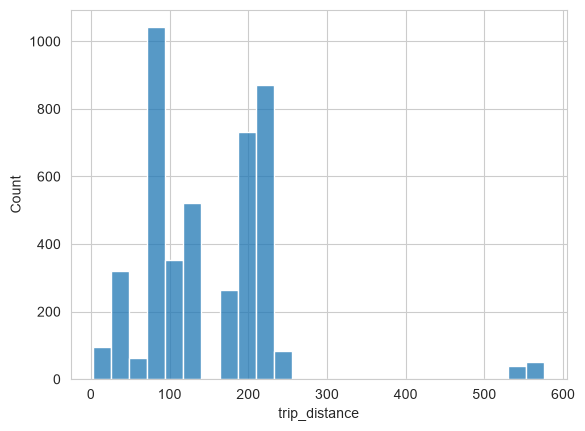

In [144]:
ax = sns.histplot(
    data=df_total,
    x='trip_distance',
    bins=25
)

plt.show()

In [154]:
df_total.sort_values(by = 'trip_distance').head(20)

,trip_id,trip_start,trip_end,trip_distance,trip_fuel,trip_from,trip_to,car_brand,car_model,car_year,...,car_active_to,employee_name,employee_surname,employee_gender,employee_year_of_birth,employee_date_of_employment,employee_employment_end_date,employee_position_name,employee_department_name,employee_department_description
3253,60960,2026-09-02,2026-09-02,3,0.26,Olsztyn,Sklep,Ford,Transit,2017,...,NaT,Roksana,Czachor,F,1973,2011-07-15,NaT,Driver,TR,Transport
3256,60963,2026-09-02,2026-09-02,3,0.26,Sklep,Olsztyn,Ford,Transit,2017,...,NaT,Roksana,Czachor,F,1973,2011-07-15,NaT,Driver,TR,Transport
3042,60749,2026-08-12,2026-08-12,3,0.24,Olsztyn,Sklep,Fiat,Ducato,2011,...,NaT,Emil,Sekula,M,1976,2018-06-27,NaT,Driver,TR,Transport
3046,60753,2026-08-12,2026-08-12,3,0.24,Sklep,Olsztyn,Fiat,Ducato,2011,...,NaT,Emil,Sekula,M,1976,2018-06-27,NaT,Driver,TR,Transport
354,48059,2023-02-06,2023-02-06,3,0.34,Olsztyn,Sklep,Ford,Transit,2013,...,NaT,Ernest,Rząca,M,1986,2007-03-26,NaT,Driver,TR,Transport
2928,60635,2026-07-31,2026-07-31,3,0.23,Olsztyn,Sklep,Opel,Insignia,2021,...,NaT,Mariola,Suchań,F,1965,2005-06-29,NaT,Chief Executive Officer,GM,General Management
1192,58899,2026-02-09,2026-02-09,3,0.27,Olsztyn,Sklep,Fiat,Ducato,2017,...,NaT,Juliusz,Ikonowicz,M,1969,2012-11-14,NaT,Driver,TR,Transport
1197,58904,2026-02-09,2026-02-09,3,0.27,Sklep,Olsztyn,Fiat,Ducato,2017,...,NaT,Juliusz,Ikonowicz,M,1969,2012-11-14,NaT,Driver,TR,Transport
2929,60636,2026-07-31,2026-07-31,3,0.23,Sklep,Olsztyn,Opel,Insignia,2021,...,NaT,Mariola,Suchań,F,1965,2005-06-29,NaT,Chief Executive Officer,GM,General Management
359,48064,2023-02-06,2023-02-06,3,0.34,Sklep,Olsztyn,Ford,Transit,2013,...,NaT,Ernest,Rząca,M,1986,2007-03-26,NaT,Driver,TR,Transport


In [155]:
#sprawdzanie dat rozpoczęcia i zakońćzenia podróży

In [157]:
invalid_trips = df_total[
    df_total["trip_start"] > df_total["trip_end"]
]

print(f"Liczba nieprawidłowych podróży: {len(invalid_trips)}")

Liczba nieprawidłowych podróży: 0


In [158]:
# czy nie użyto samochodów nieaktywnych

invalid_car_usage = df_total[
    df_total["car_active_to"].notna()
    & (df_total["trip_end"] > df_total["car_active_to"])
]

print(f"Liczba nieprawidłowych podróży: {len(invalid_car_usage)}")

Liczba nieprawidłowych podróży: 0


In [159]:
# czy podróż rozpoczęła się po zakończeniu aktywności samochodu
invalid_car_start = df_total[
    df_total["car_active_to"].notna()
    & (df_total["trip_start"] > df_total["car_active_to"])
]

print(f"Liczba podróży rozpoczętych po wycofaniu samochodu: {len(invalid_car_start)}")

Liczba podróży rozpoczętych po wycofaniu samochodu: 0


In [160]:
# czy podróże wykonane przed zatrudnieniem
trips_before_employment = df_total[
    df_total["trip_start"] < df_total["employee_date_of_employment"]
]

print(f"Liczba podróży przed zatrudnieniem: {len(trips_before_employment)}")

Liczba podróży przed zatrudnieniem: 0


In [161]:
# podróże wykonane po zakończeniu zatrudnienia
trips_after_employment = df_total[
    df_total["employee_employment_end_date"].notna()
    & (
        df_total["trip_end"]
        > df_total["employee_employment_end_date"]
    )
]

print(f"Liczba podróży po zakończeniu zatrudnienia: {len(trips_after_employment)}")

Liczba podróży po zakończeniu zatrudnienia: 0


In [ ]:
# sprawdzenie długości tras na tych sdamych trasach

In [163]:
df_total['route'] = np.where(
    df_total['trip_from'] < df_total['trip_to'],
    df_total['trip_from'] + ' ↔ ' + df_total['trip_to'],
    df_total['trip_to'] + ' ↔ ' + df_total['trip_from']
)

In [164]:
df_total.dtypes

trip_id                                     int64
trip_start                         datetime64[us]
trip_end                           datetime64[us]
trip_distance                               int64
trip_fuel                                 float64
trip_from                                     str
trip_to                                       str
car_brand                                     str
car_model                                     str
car_year                                    int64
car_fuel_type                                 str
car_transport                                bool
car_active                                    str
car_active_from                    datetime64[us]
car_active_to                      datetime64[us]
employee_name                                 str
employee_surname                              str
employee_gender                               str
employee_year_of_birth                      int64
employee_date_of_employment        datetime64[us]


In [166]:
df_total.groupby('route')['trip_distance'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
route,,,,,,,,
Bartoszyce ↔ Olsztyn,536.0,73.53,1.61,71.0,72.0,73.5,75.0,76.0
Bydgoszcz ↔ Olsztyn,544.0,219.54,4.60,212.0,215.0,220.0,223.0,228.0
Elbląg ↔ Olsztyn,378.0,113.92,2.44,110.0,112.0,114.0,116.0,118.0
Gdańsk ↔ Olsztyn,486.0,197.39,4.02,190.0,194.0,197.0,201.0,204.0
Malbork ↔ Olsztyn,494.0,134.87,2.77,130.0,133.0,135.0,137.0,140.0
Mikołajki ↔ Olsztyn,570.0,87.09,1.82,84.0,85.0,87.0,89.0,90.0
Olsztyn ↔ Ostróda,320.0,41.52,0.90,40.0,41.0,42.0,42.0,43.0
Olsztyn ↔ Sklep,38.0,4.58,1.62,3.0,3.0,4.0,5.0,8.0
Olsztyn ↔ Szczecin,90.0,557.58,11.86,538.0,547.0,560.0,566.0,576.0


In [167]:
# Mediana długości dla każdej trasy
df_total["route_median"] = (
    df_total.groupby("route")["trip_distance"]
    .transform("median")
)

# Procentowe odchylenie od mediany
df_total["distance_deviation_pct"] = (
    (df_total["trip_distance"] - df_total["route_median"])
    / df_total["route_median"]
    * 100
)

In [168]:
suspicious_trips = df_total[
    df_total["distance_deviation_pct"] > 10
]

print("Liczba potencjalnie podejrzanych podróży:", len(suspicious_trips))

Liczba potencjalnie podejrzanych podróży: 30


In [171]:
suspicious_trips[
    [
        "trip_id",
        "route",
        "trip_distance",
        "route_median",
        "distance_deviation_pct",
        "employee_name",
        "employee_surname"
    ]
].sort_values("distance_deviation_pct", ascending=False).reset_index()

,index,trip_id,route,trip_distance,route_median,distance_deviation_pct,employee_name,employee_surname
0,702,48407,Olsztyn ↔ Sklep,8,4.0,100.000000,Mariola,Suchań
1,703,48408,Olsztyn ↔ Sklep,8,4.0,100.000000,Mariola,Suchań
2,210,47915,Olsztyn ↔ Sklep,7,4.0,75.000000,Jadwiga,Gall
3,206,47911,Olsztyn ↔ Sklep,7,4.0,75.000000,Jadwiga,Gall
4,819,48524,Olsztyn ↔ Sklep,7,4.0,75.000000,Jadwiga,Gall
5,813,48518,Olsztyn ↔ Sklep,7,4.0,75.000000,Jadwiga,Gall
6,3564,61271,Olsztyn ↔ Sklep,7,4.0,75.000000,Fryderyk,Przybylski
7,3560,61267,Olsztyn ↔ Sklep,7,4.0,75.000000,Fryderyk,Przybylski
8,1022,58729,Olsztyn ↔ Urząd,11,7.0,57.142857,Roksana,Czachor
9,1026,58733,Olsztyn ↔ Urząd,11,7.0,57.142857,Roksana,Czachor


In [172]:
df_total["fuel_per_100km"] = np.where(
    df_total["trip_distance"] > 0,
    df_total["trip_fuel"] / df_total["trip_distance"] * 100,
    np.nan
)

In [173]:
df_total["fuel_per_100km"].describe()

count    4432.000000
mean       11.596001
std         5.102204
min         5.421053
25%         8.930525
50%         9.989583
75%        10.880952
max        30.714286
Name: fuel_per_100km, dtype: float64

In [174]:
car_cols = [
    "car_brand",
    "car_model",
    "car_year",
    "car_fuel_type"
]

In [175]:
fuel_stats = (
    df_total
    .groupby(car_cols)["fuel_per_100km"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

fuel_stats

count   mean  median   std   min  \
car_brand car_model car_year car_fuel_type                                     
Fiat      Ducato    2011     ON              1210  11.05    9.53  4.55  7.87   
                    2017     ON               614  11.02    9.14  4.52  7.87   
Ford      Transit   2013     ON              1126  12.57   10.22  5.68  8.80   
                    2017     ON              1196  12.49   10.65  5.34  8.67   
Opel      Insignia  2021     PB               286   7.57    7.65  0.39  5.42   

                                              max  
car_brand car_model car_year car_fuel_type         
Fiat      Ducato    2011     ON             27.44  
                    2017     ON             27.44  
Ford      Transit   2013     ON             30.71  
                    2017     ON             30.71  
Opel      Insignia  2021     PB              7.75

In [176]:
df_total[["trip_distance", "trip_fuel"]].corr()

,trip_distance,trip_fuel
trip_distance,1.0000,0.7493
trip_fuel,0.7493,1.0000


In [177]:
df_total["car_fuel_median"] = (
    df_total
    .groupby(car_cols)["fuel_per_100km"]
    .transform("median")
)

In [178]:
df_total["fuel_deviation_pct"] = (
    (df_total["fuel_per_100km"] - df_total["car_fuel_median"])
    / df_total["car_fuel_median"]
    * 100
)

In [189]:
suspicious_fuel = df_total[
    (df_total["fuel_deviation_pct"] > 50)
    & (df_total["car_fuel_median"] > 0)
].copy()

In [190]:
suspicious_fuel[
    [
        "trip_id",
        "car_brand",
        "car_model",
        "trip_distance",
        "trip_fuel",
        "fuel_per_100km",
        "car_fuel_median",
        "fuel_deviation_pct",
        "employee_name",
        "employee_surname"
    ]
].sort_values(
    "fuel_deviation_pct",
    ascending=False
).round(2)

,trip_id,car_brand,car_model,trip_distance,trip_fuel,fuel_per_100km,car_fuel_median,fuel_deviation_pct,employee_name,employee_surname
31,47736,Ford,Transit,7,2.15,30.71,10.22,200.44,Emil,Sekula
36,47741,Ford,Transit,7,2.15,30.71,10.22,200.44,Emil,Sekula
3080,60787,Ford,Transit,43,13.20,30.70,10.22,200.28,Emil,Sekula
3086,60793,Ford,Transit,43,13.20,30.70,10.22,200.28,Emil,Sekula
516,48221,Ford,Transit,42,12.89,30.69,10.22,200.21,Emil,Sekula
...,...,...,...,...,...,...,...,...,...,...
2486,60193,Fiat,Ducato,42,8.40,20.00,9.53,109.85,Magdalena,Dobrzyńska
658,48363,Fiat,Ducato,42,8.40,20.00,9.53,109.85,Magdalena,Dobrzyńska
653,48358,Fiat,Ducato,42,8.40,20.00,9.53,109.85,Magdalena,Dobrzyńska
998,58705,Fiat,Ducato,42,8.40,20.00,9.53,109.85,Magdalena,Dobrzyńska


In [191]:
print("Liczba wierszy:", len(df_total))
print("Liczba unikalnych podróży:", df_total["trip_id"].nunique())
print("Liczba zduplikowanych trip_id:", df_total["trip_id"].duplicated().sum())

Liczba wierszy: 4432
Liczba unikalnych podróży: 4432
Liczba zduplikowanych trip_id: 0


In [185]:
df_total.dtypes

trip_id                                     int64
trip_start                         datetime64[us]
trip_end                           datetime64[us]
trip_distance                               int64
trip_fuel                                 float64
trip_from                                     str
trip_to                                       str
car_brand                                     str
car_model                                     str
car_year                                    int64
car_fuel_type                                 str
car_transport                                bool
car_active                                    str
car_active_from                    datetime64[us]
car_active_to                      datetime64[us]
employee_name                                 str
employee_surname                              str
employee_gender                               str
employee_year_of_birth                      int64
employee_date_of_employment        datetime64[us]


In [192]:
# Kolumny definiujące identyczny przejazd
group_cols = [
    "car_brand",
    "car_model",
    "trip_distance",
    "trip_fuel",
    "fuel_per_100km",
    "car_fuel_median",
    "fuel_deviation_pct",
    "employee_name",
    "employee_surname"
]

# Grupowanie i zliczanie identycznych przejazdów
suspicious_fuel_grouped = (
    suspicious_fuel
    .groupby(group_cols, dropna=False)
    .agg(
        count=("trip_id", "count")
    )
    .reset_index()
    .sort_values("fuel_deviation_pct", ascending=False)
    .round(2)
)

suspicious_fuel_grouped

,car_brand,car_model,trip_distance,trip_fuel,fuel_per_100km,car_fuel_median,fuel_deviation_pct,employee_name,employee_surname,count
100,Ford,Transit,7,2.15,30.71,10.22,200.44,Emil,Sekula,2
111,Ford,Transit,43,13.20,30.70,10.22,200.28,Emil,Sekula,2
108,Ford,Transit,42,12.89,30.69,10.22,200.21,Emil,Sekula,2
147,Ford,Transit,113,34.68,30.69,10.22,200.21,Emil,Sekula,2
132,Ford,Transit,87,26.70,30.69,10.22,200.20,Emil,Sekula,2
...,...,...,...,...,...,...,...,...,...,...
32,Fiat,Ducato,133,26.61,20.01,9.53,109.93,Magdalena,Dobrzyńska,2
35,Fiat,Ducato,134,26.81,20.01,9.53,109.93,Magdalena,Dobrzyńska,2
3,Fiat,Ducato,42,8.40,20.00,9.53,109.85,Magdalena,Dobrzyńska,6
4,Fiat,Ducato,43,8.60,20.00,9.53,109.85,Magdalena,Dobrzyńska,2


In [199]:
employee_fuel_summary = (
    suspicious_fuel
    .groupby([
        "employee_name",
        "employee_surname",
        "employee_department_name"
    ], dropna=False)
    .agg(
        suspicious_trips=("trip_id", "nunique"),
        cars=("car", lambda x: "\n".join(sorted(x.dropna().unique()))),
        routes=("route", lambda x: "\n".join(sorted(x.dropna().unique())))
    )
    .reset_index()
    .sort_values("suspicious_trips", ascending=False)
)

display(
    employee_fuel_summary.style.set_properties(
        subset=["routes", "cars"],
        **{"white-space": "pre-line"}
    )
)

,employee_name,employee_surname,employee_department_name,suspicious_trips,cars,routes
1,Magdalena,Dobrzyńska,TR,544,Fiat Ducato Ford Transit,Bartoszyce ↔ Olsztyn Bydgoszcz ↔ Olsztyn Elbląg ↔ Olsztyn Gdańsk ↔ Olsztyn Malbork ↔ Olsztyn Mikołajki ↔ Olsztyn Olsztyn ↔ Ostróda Olsztyn ↔ Szczecin Olsztyn ↔ Toruń Olsztyn ↔ Urząd Olsztyn ↔ Warszawa
0,Emil,Sekula,TR,126,Fiat Ducato Ford Transit,Bartoszyce ↔ Olsztyn Bydgoszcz ↔ Olsztyn Elbląg ↔ Olsztyn Gdańsk ↔ Olsztyn Malbork ↔ Olsztyn Mikołajki ↔ Olsztyn Olsztyn ↔ Ostróda Olsztyn ↔ Sklep Olsztyn ↔ Szczecin Olsztyn ↔ Toruń Olsztyn ↔ Urząd Olsztyn ↔ Warszawa
